# 5e — Animated flood-scenario basins, Costa Rica

## Purpose

An animated GIF that steps through every basin scenario of notebook 5b, **one basin per frame**,
showing the **flood-exposed road segments** that the scenario removes. Nothing else is shown:
**no travel-time impact, no delay classes** — only where the flooded roads are.

> ### ⚠ Exposure, not risk
> A scenario removes every flood-exposed road in one basin with certainty (see 5b/5c). Each frame is
> **one basin evaluated alone** — never a national event, and the frames are not cumulative.

## Inputs

| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` (`main_network_directed`) | CR road network, EPSG:8908 |
| `intermediate_results/parquet/flood_scenarios/scenario_edges.parquet` | 5b partition: physical road → basin `scenario_id` |
| `intermediate_results/gpkg/travel_disruptions/flood_scenario_accessibility.gpkg` (`scenarios`) | Basin polygons from 5b |

## Outputs

| File | Description |
|------|-------------|
| `figures/flood_scenario_basins.gif` | One frame per basin, plus an overview frame |

## Assumptions (user said "go with the defaults")

* **Order:** basins sorted by 5b's mean delay (`loc` origins, hospitals, unbuffered), largest first.
  The delay is used **only to order** the frames; it is not displayed.
* **Segments:** the whole physical road that 5b removes (not only the sub-stretch under water).
* **Frames:** one basin each (not cumulative), preceded by an overview of all basins.

In [1]:
import io
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as IPImage, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image
from tqdm.auto import tqdm

BASE_DIR = Path.cwd().parent
sys.path.append(str(BASE_DIR))
from src.map_style_cr import style_cr_map

warnings.simplefilter(action="ignore", category=FutureWarning)

WEB_MERCATOR = 3857      # basemap tiles only
WORKING_EPSG = 8908

# ---- GIF settings ------------------------------------------------------
FRAME_MS = 900           # per basin frame
OVERVIEW_MS = 2000       # overview frame (all basins)
FIG_SIZE = (8.5, 7.0)
DPI = 110
FORCE_REGEN = False      # True = re-render even if the GIF exists

ORDER_ORIGIN_SET, ORDER_SECTOR = "loc", "hospitals"   # used for ordering only

FLOOD_ROAD_COLOR = "#08519c"
BASIN_FILL = "#9ecae1"

parquet_dir = BASE_DIR / "intermediate_results" / "parquet" / "flood_scenarios"
gpkg_dir = BASE_DIR / "intermediate_results" / "gpkg"
figure_path = BASE_DIR / "figures"
figure_path.mkdir(exist_ok=True)

edges_parquet = parquet_dir / "scenario_edges.parquet"
scenario_gpkg = gpkg_dir / "travel_disruptions" / "flood_scenario_accessibility.gpkg"
network_gpkg = gpkg_dir / "network" / "main_network_directed.gpkg"
gif_path = figure_path / "flood_scenario_basins.gif"

missing = [p for p in (edges_parquet, scenario_gpkg, network_gpkg) if not p.exists()]
if missing:
    raise FileNotFoundError("Missing inputs (run 5b first):\n  " + "\n  ".join(map(str, missing)))

/Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/src/map_style_cr.py:148: RuntimeWarning: Font 'Aptos' not installed; using matplotlib's default font.
  warnings.warn(f"Font '{FONT_FAMILY}' not installed; using matplotlib's default font.",


## 1 · Data

In [2]:
network = gpd.read_file(network_gpkg, layer="main_network_directed")
assert network.crs.to_epsg() == WORKING_EPSG

# One geometry per physical road - the unit 5b removes.
roads = (network.dissolve("physical_edge_id", aggfunc={"road_length": "sum"})
         .reset_index()[["physical_edge_id", "road_length", "geometry"]])
scenario_edges = pd.read_parquet(edges_parquet)
assert scenario_edges["physical_edge_id"].is_unique, "partition is no longer 1:1"
flooded = roads.merge(scenario_edges, on="physical_edge_id", how="inner", validate="1:1")

# Basin polygons plus the ordering key (the delay is NOT drawn).
raw = gpd.read_file(scenario_gpkg, layer="scenarios")
order_rows = raw[(raw["origin_set"] == ORDER_ORIGIN_SET) & (raw["sector"] == ORDER_SECTOR)
                 & (~raw["buffered"].astype(bool))]
assert order_rows["scenario_id"].is_unique, "ordering rows are not unique per scenario"
basins = order_rows[["scenario_id", "mean_delta_min", "geometry"]].sort_values(
    "mean_delta_min", ascending=False).reset_index(drop=True)
assert set(basins["scenario_id"]) == set(flooded["scenario_id"]), "basins and roads disagree"

net_3857 = network.to_crs(WEB_MERCATOR)
basins_3857 = basins.to_crs(WEB_MERCATOR)
flooded_3857 = flooded.to_crs(WEB_MERCATOR)

print(f"Basin scenarios      : {len(basins)}")
print(f"Flood-exposed roads  : {len(flooded)}  ({flooded['road_length'].sum():,.0f} km)")
print(f"Frames               : {len(basins)} + 1 overview")

Basin scenarios      : 65
Flood-exposed roads  : 378  (4,839 km)
Frames               : 65 + 1 overview


## 2 · Render

The map is styled **once** with `style_cr_map` (basemap, outline, cities, legend). Each frame only adds
and removes the basin polygon, its flooded roads and the caption, so tiles are not re-fetched per
frame.

In [3]:
def render_gif():
    fig, ax = plt.subplots(figsize=FIG_SIZE, facecolor="white")
    net_3857.plot(ax=ax, linewidth=0.2, color="lightgrey", alpha=0.6)
    # Static: faint outlines of all basins, for context.
    basins_3857.boundary.plot(ax=ax, color="#6baed6", linewidth=0.4, alpha=0.6, zorder=3)
    style_cr_map(
        ax, WEB_MERCATOR,
        legend_handles=[
            Patch(facecolor=BASIN_FILL, edgecolor="navy", alpha=0.6, label="Basin scenario"),
            Line2D([0], [0], color=FLOOD_ROAD_COLOR, linewidth=2.5, label="Flooded road segment"),
        ],
        legend_title="RP100 flood-exposed roads",
        legend_kw=dict(fontsize=7, title_fontsize=8),
    )
    title = ax.set_title("", fontsize=10)
    caption = ax.text(0.98, 0.97, "", transform=ax.transAxes, fontsize=8, zorder=30,
                      ha="right", va="top",
                      bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85))

    def snap():
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=DPI, bbox_inches="tight", facecolor="white")
        buf.seek(0)
        return Image.open(buf).convert("RGB")

    frames, durations = [], []

    # Overview: every basin and every flooded road.
    arts = [basins_3857.plot(ax=ax, color=BASIN_FILL, edgecolor="navy", linewidth=0.3,
                             alpha=0.5, zorder=4).collections[-1],
            flooded_3857.plot(ax=ax, color=FLOOD_ROAD_COLOR, linewidth=1.2, zorder=6).collections[-1]]
    title.set_text("All basin scenarios - exposure screen, not risk")
    caption.set_text(f"{len(basins)} basins  |  {len(flooded)} flooded roads  |  "
                     f"{flooded['road_length'].sum():,.0f} km")
    frames.append(snap()); durations.append(OVERVIEW_MS)
    for a in arts:
        a.remove()

    for i, row in tqdm(basins_3857.iterrows(), total=len(basins_3857), desc="frames"):
        sid = row["scenario_id"]
        sub = flooded_3857[flooded_3857["scenario_id"] == sid]
        arts = [
            gpd.GeoSeries([row.geometry], crs=WEB_MERCATOR).plot(
                ax=ax, color=BASIN_FILL, edgecolor="navy", linewidth=0.8, alpha=0.6, zorder=4
            ).collections[-1],
            sub.plot(ax=ax, color=FLOOD_ROAD_COLOR, linewidth=2.5, zorder=6).collections[-1],
        ]
        title.set_text(f"Basin scenario {sid}   ({i + 1} / {len(basins_3857)})")
        caption.set_text(f"{len(sub)} flooded roads  |  {sub['road_length'].sum():,.1f} km")
        frames.append(snap()); durations.append(FRAME_MS)
        for a in arts:
            a.remove()
    plt.close(fig)

    # Common size (bbox_inches='tight' can differ by a pixel) and one shared palette.
    w, h = frames[0].size
    frames = [f.resize((w, h)) for f in frames]
    pal = frames[0].quantize(colors=255, method=Image.Quantize.MEDIANCUT)
    q = [f.quantize(palette=pal, dither=Image.Dither.NONE) for f in frames]
    q[0].save(gif_path, save_all=True, append_images=q[1:], duration=durations,
              loop=0, optimize=False, disposal=2)
    return len(frames)


if gif_path.exists() and not FORCE_REGEN:
    print(f"{gif_path.name} exists - skipped (set FORCE_REGEN = True to re-render).")
else:
    n = render_gif()
    print(f"Wrote {gif_path}  ({n} frames)")

frames:   0%|          | 0/65 [00:00<?, ?it/s]

Wrote /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/figures/flood_scenario_basins.gif  (66 frames)


## 3 · Check and display

Frames in file : 66  (expected 66)
Pixel size     : (646, 636)
File size      : 5.8 MB


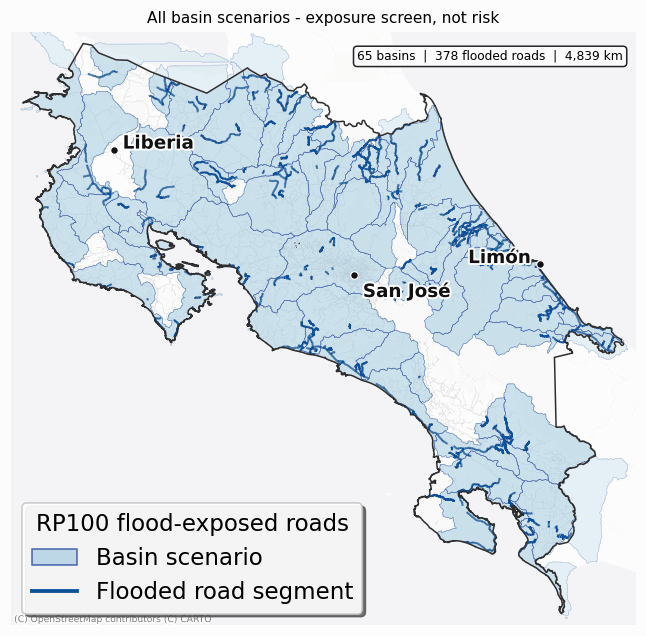

In [4]:
with Image.open(gif_path) as g:
    n_frames = g.n_frames
    size = g.size
print(f"Frames in file : {n_frames}  (expected {len(basins) + 1})")
print(f"Pixel size     : {size}")
print(f"File size      : {gif_path.stat().st_size / 1e6:.1f} MB")
assert n_frames == len(basins) + 1
# Every flooded road is drawn exactly once across the basin frames.
assert flooded.groupby("scenario_id").size().sum() == len(flooded)
display(IPImage(filename=str(gif_path)))